In [2]:
import pandas as pd
import numpy as np

# Load
results = pd.read_csv("fact_Results.csv")
races   = pd.read_csv("dim_Races.csv")
drivers = pd.read_csv("dim_Drivers.csv")
circuits= pd.read_csv("dim_Circuits.csv")

# Replace \N with NaN across all tables
for df in [results, races, drivers, circuits]:
    df.replace('\\N', np.nan, inplace=True)

# --- fact_Results ---
results['driver_name'] = results['driver_name'].str.strip()
results['points'] = pd.to_numeric(results['points'], errors='coerce').fillna(0).astype(int)
results['position_clean'] = pd.to_numeric(
    results['position'].replace({'R': np.nan, 'F': np.nan}), errors='coerce'
)
results['dnf'] = results['position'].isin(['R', 'F']).astype(int)

# --- dim_Races ---
races['race_date'] = pd.to_datetime(races['race_date'], errors='coerce')

# --- dim_Drivers ---
drivers['driver_name'] = drivers['driver_name'].str.strip()
drivers['race_number'] = pd.to_numeric(drivers['race_number'], errors='coerce').fillna(0).astype(int)

# --- dim_Circuits ---
circuits['altitude'] = pd.to_numeric(circuits['altitude'], errors='coerce').fillna(0).astype(int)

print("✅ All tables cleaned")

✅ All tables cleaned


In [3]:
# Merge results → races → circuits → drivers
df = results.merge(races, on=['season_year', 'round_number'], how='left')
df = df.merge(circuits, on='circuit_name', how='left')
df = df.merge(drivers, on='driver_name', how='left')

print(df.shape)
df.head()

(25840, 31)


,result_id,season_year,round_number,driver_name,team,grid,position,points,laps,total_time,...,circuit_name,country_x,location,country_y,lat,lng,altitude,nationality,date_of_birth,race_number
0,RES00001,1950,1,Nino Farina,Alfa Romeo,1,1,9,70,2:13:23.6,...,Silverstone Circuit,UK,Silverstone,UK,52.0786,-1.01694,153,Italian,1906-10-30,2
1,RES00002,1950,1,Luigi Fagioli,Alfa Romeo,2,2,6,70,+2.6,...,Silverstone Circuit,UK,Silverstone,UK,52.0786,-1.01694,153,Italian,1898-06-09,3
2,RES00003,1950,1,Reg Parnell,Alfa Romeo,4,3,4,70,+52.0,...,Silverstone Circuit,UK,Silverstone,UK,52.0786,-1.01694,153,British,1911-07-02,4
3,RES00004,1950,1,Yves Cabantous,Talbot-Lago,6,4,3,68,NaN,...,Silverstone Circuit,UK,Silverstone,UK,52.0786,-1.01694,153,French,1904-10-08,14
4,RES00005,1950,1,Louis Rosier,Talbot-Lago,9,5,2,68,NaN,...,Silverstone Circuit,UK,Silverstone,UK,52.0786,-1.01694,153,French,1905-11-05,15


In [4]:
# ── Q1: Most consistent driver (Podium Rate, min 50 races) ──
finished = df[df['position_clean'].notna()]
podium   = finished[finished['position_clean'] <= 3]

podium_rate = (
    podium.groupby('driver_name').size() /
    finished.groupby('driver_name').size()
).dropna()

top_consistent = podium_rate[finished.groupby('driver_name').size() >= 50] \
                 .sort_values(ascending=False).head(10)
print("── Most Consistent Drivers (Podium Rate %) ──")
print((top_consistent * 100).round(2))

# ── Q2: Circuit with most DNFs ──
dnf_by_circuit = df[df['dnf'] == 1].groupby('circuit_name').size().sort_values(ascending=False).head(10)
print("\n── Most DNFs by Circuit ──")
print(dnf_by_circuit)

# ── Q3: Team dominance by circuit type ──
# Tag street circuits manually (known list)
street_circuits = ['Circuit de Monaco', 'Baku City Circuit', 'Marina Bay Street Circuit',
                   'Valencia Street Circuit', 'Circuit urbain de Monaco']
df['circuit_type'] = df['circuit_name'].apply(
    lambda x: 'Street' if x in street_circuits else 'Track'
)
team_circuit = df.groupby(['circuit_type', 'team'])['points'].sum() \
                 .reset_index().sort_values('points', ascending=False)
print("\n── Top Teams by Circuit Type ──")
print(team_circuit.groupby('circuit_type').head(3))

# ── Q4: Championship competitiveness (points gap P1 vs P2 per season) ──
season_points = df.groupby(['season_year', 'driver_name'])['points'].sum().reset_index()
season_points = season_points.sort_values(['season_year', 'points'], ascending=[True, False])

def points_gap(group):
    top2 = group.nlargest(2, 'points')
    if len(top2) == 2:
        return top2.iloc[0]['points'] - top2.iloc[1]['points']
    return np.nan

competitiveness = season_points.groupby('season_year').apply(points_gap).reset_index()
competitiveness.columns = ['season_year', 'points_gap']
print("\n── Championship Points Gap P1 vs P2 (last 10 seasons) ──")
print(competitiveness.tail(10))

# ── Q5: Best driver to recommend (Win Rate + Podium Rate, last 5 seasons) ──
recent = df[df['season_year'] >= 2018]
recent_finished = recent[recent['position_clean'].notna()]

win_rate   = (recent_finished[recent_finished['position_clean'] == 1]
              .groupby('driver_name').size() /
              recent_finished.groupby('driver_name').size()).dropna()

podium_rate_recent = (recent_finished[recent_finished['position_clean'] <= 3]
                      .groupby('driver_name').size() /
                      recent_finished.groupby('driver_name').size()).dropna()

recommendation = pd.DataFrame({
    'win_rate':    win_rate,
    'podium_rate': podium_rate_recent
}).dropna()

recommendation = recommendation[
    recent_finished.groupby('driver_name').size() >= 20  # min 20 races
].sort_values('podium_rate', ascending=False).head(5)

print("\n── Driver Recommendation (2018–2022) ──")
print((recommendation * 100).round(2))

── Most Consistent Drivers (Podium Rate %) ──
driver_name
Alain Prost           74.13
Ayrton Senna          74.07
Jackie Stewart        68.25
Lewis Hamilton        67.25
Michael Schumacher    64.32
Jim Clark             64.00
Nigel Mansell         60.20
Niki Lauda            59.34
Max Verstappen        57.46
Damon Hill            54.55
dtype: float64

── Most DNFs by Circuit ──
circuit_name
Circuit de Monaco                807
Autodromo Nazionale di Monza     767
Silverstone Circuit              524
Circuit de Spa-Francorchamps     434
Circuit Gilles Villeneuve        433
Hockenheimring                   422
Nürburgring                      402
Autodromo Enzo e Dino Ferrari    348
Red Bull Ring                    338
Circuit Park Zandvoort           317
dtype: int64

── Top Teams by Circuit Type ──
    circuit_type      team  points
196        Track   Ferrari    9093
262        Track  Mercedes    6229
257        Track   McLaren    5551
40        Street   Ferrari    1035
94        Stree

/tmp/ipykernel_4850/3685464007.py:42: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  competitiveness = season_points.groupby('season_year').apply(points_gap).reset_index()
/tmp/ipykernel_4850/3685464007.py:64: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  recommendation = recommendation[


In [5]:
results_export = results.copy()
results_export['position'] = results_export['position_clean']  # clean position col
results_export.drop(columns=['position_clean'], inplace=True)

results_export.to_csv("fact_Results_clean.csv", index=False)
races.to_csv("dim_Races_clean.csv", index=False)
drivers.to_csv("dim_Drivers_clean.csv", index=False)
circuits.to_csv("dim_Circuits_clean.csv", index=False)

print("✅ Clean CSVs exported — hand to Power BI teammates")

✅ Clean CSVs exported — hand to Power BI teammates


              precision    recall  f1-score   support

           0       0.89      0.91      0.90      2346
           1       0.66      0.60      0.63       653

    accuracy                           0.84      2999
   macro avg       0.77      0.76      0.76      2999
weighted avg       0.84      0.84      0.84      2999



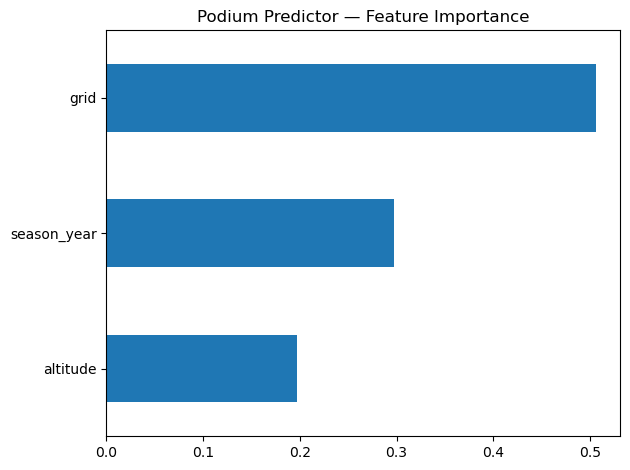

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

model_df = df[['grid', 'points', 'season_year', 'altitude', 'dnf', 'position_clean']].dropna()
model_df['podium'] = (model_df['position_clean'] <= 3).astype(int)

X = model_df[['grid', 'season_year', 'altitude']]
y = model_df['podium']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf.fit(X_train, y_train)
print(classification_report(y_test, clf.predict(X_test)))

# Feature importance → hand to Person 3 as a visual
import matplotlib.pyplot as plt
import pandas as pd

pd.Series(clf.feature_importances_, index=X.columns) \
  .sort_values().plot(kind='barh', title='Podium Predictor — Feature Importance')
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)